# Diabetes Progression Prediction using Support Vector Regression (SVR)

## Project Overview
In this project, I use Support Vector Regression (SVR) to predict diabetes disease progression using the Diabetes dataset provided by Scikit-learn.

The goal is to understand the complete regression workflow, including exploratory data analysis (EDA), preprocessing, cross-validation, hyperparameter tuning, and model evaluation.

### Dataset
- Source: Scikit-learn built-in Diabetes dataset
- Number of observations: 442
- Number of input features: 10
- Target: A quantitative measure of disease progression one year after baseline

Note: This dataset is intended for learning and research. The model is not a medical diagnostic tool.


## 1. Import Libraries

We import the libraries required for data handling, visualization, preprocessing, model training, cross-validation, and evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)



## 2. Load Dataset

`load_diabetes()` loads the dataset included with Scikit-learn. We convert the feature data into a Pandas DataFrame and add the target column.

In [2]:
diabetes = load_diabetes()

df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df["Target"] = diabetes.target

df.head()


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 3. Understand the Dataset

We use `shape`, `info()` and `describe()` to understand the dataset's dimensions, data types, missing values, and statistical summary.

In [3]:
print("Dataset shape:", df.shape)
print("\\nDataset information:")
df.info()


Dataset shape: (442, 11)
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  Target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [4]:
df.describe()


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


## 4. Check Missing Values and Duplicates

We check whether the dataset contains missing values or duplicate rows. This helps identify basic data-quality issues before analysis.

In [5]:
print("Missing values:")
print(df.isnull().sum())

print("\\nDuplicate rows:", df.duplicated().sum())


Missing values:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
Target    0
dtype: int64
\nDuplicate rows: 0


## 5. Target Variable Distribution

A histogram with a KDE curve helps us understand how the target values are distributed.

Interpretation of this graph:
- Most observations are concentrated around the middle target-value range, rather than being evenly spread across the full range.
- The distribution has a positive (right) skew (skewness approximately 0.44), meaning a longer tail extends towards higher progression values.
- The target ranges from 25 to 346; its mean is 152.1, while its median is 140.5.
- This tells us that a smaller number of observations have relatively high target values. The target is therefore not perfectly symmetric.


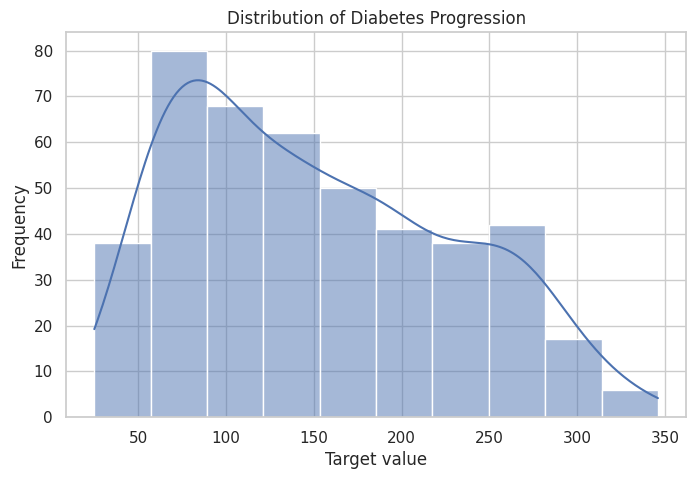

In [6]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Target"], kde=True)
plt.title("Distribution of Diabetes Progression")
plt.xlabel("Target value")
plt.ylabel("Frequency")
plt.show()


## 6. Feature Distributions

Histograms help us inspect the distributions of all ten input features.

Interpretation of these graphs:
- All ten features are centered around zero because Scikit-learn provides these predictors in a standardized form.
- The shapes are not identical: some features are fairly balanced, while others show noticeable skewness.
- The feature with the largest absolute skewness in this dataset is `s3` (skewness approximately 0.80), so its histogram is more asymmetric than the others.
- These plots help us see that standardizing the features does not make every feature normally distributed.


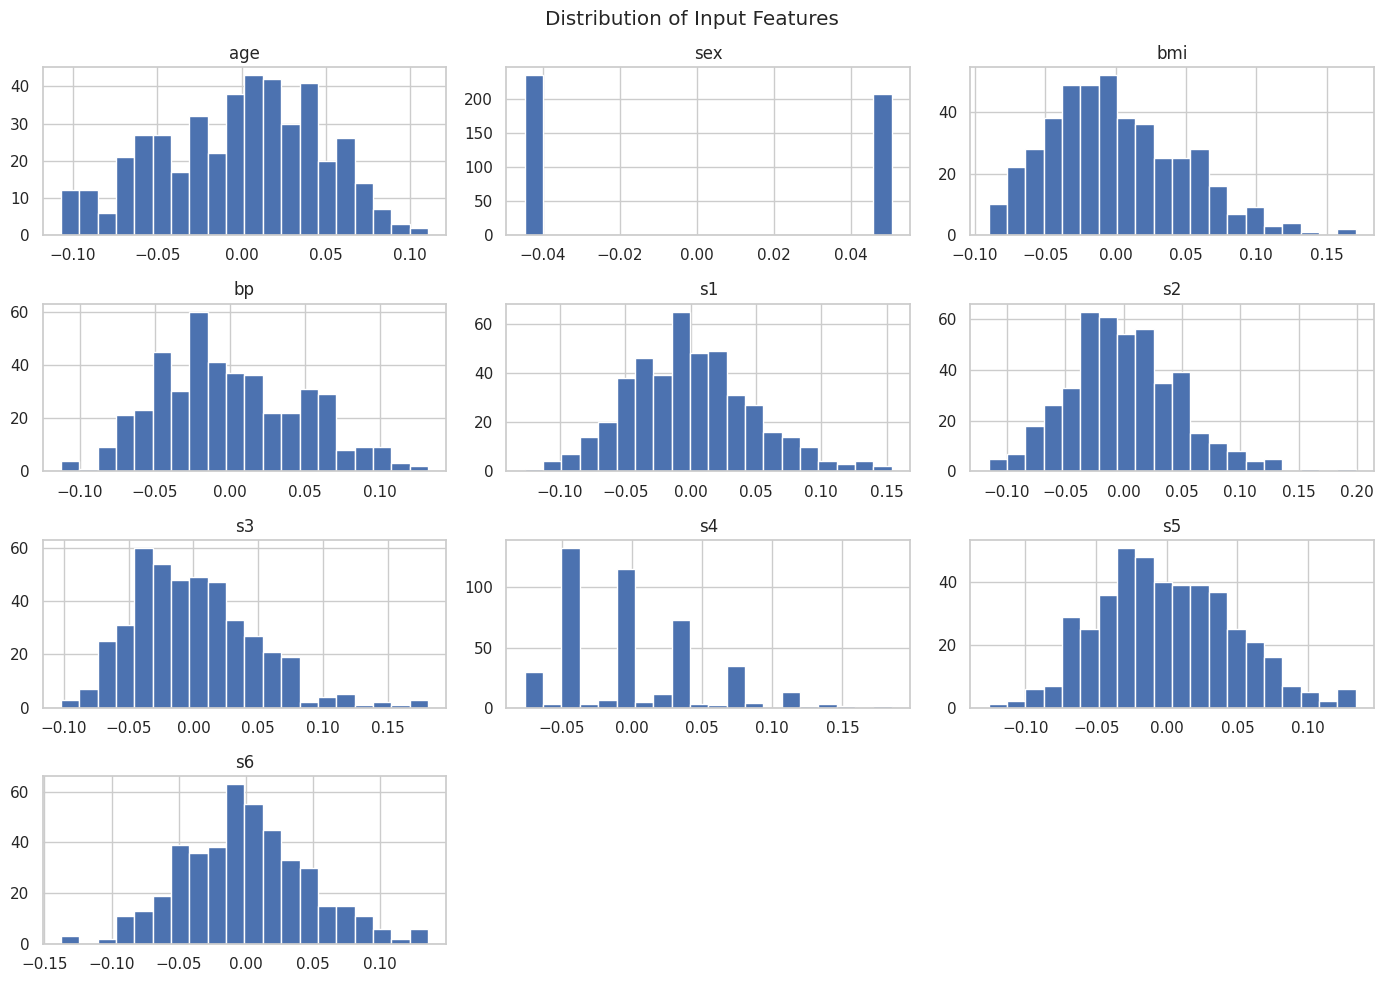

In [7]:
df.drop(columns="Target").hist(figsize=(14, 10), bins=20)
plt.suptitle("Distribution of Input Features")
plt.tight_layout()
plt.show()


## 7. Boxplots to Identify Potential Outliers

Boxplots display the median, quartiles, and potential outliers for each feature.

Interpretation of this graph:
- The boxes are generally positioned around zero, which is consistent with the standardized feature values.
- Some features have points beyond the whiskers, indicating potential outliers under the 1.5 × IQR rule.
- `s6` has the largest number of such points (9) among the input features.
- These points are only potential outliers. We keep them because an unusual value is not necessarily incorrect, and removing it without a reason could discard useful information.


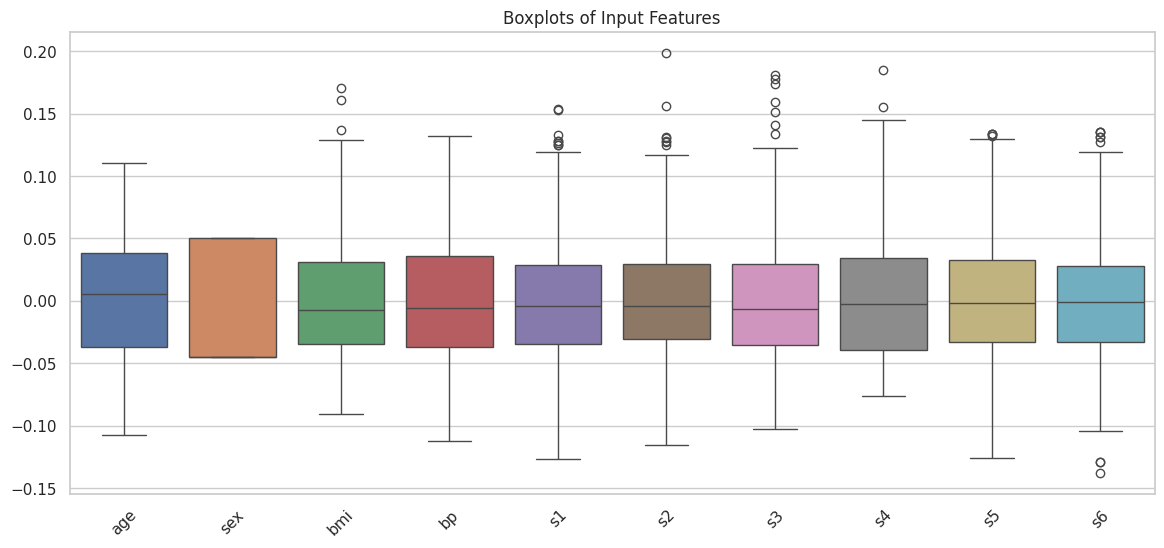

In [8]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=df.drop(columns="Target"))
plt.title("Boxplots of Input Features")
plt.xticks(rotation=45)
plt.show()


## 8. Correlation Analysis

A correlation heatmap helps us examine the direction and strength of linear relationships between numerical variables.

Interpretation of this heatmap:
- The strongest positive correlation with the target is `bmi` (approximately 0.59). In this dataset, higher values of this feature tend to be associated with higher target values.
- The strongest negative correlation with the target is `s3` (approximately -0.39). Higher values of this feature tend to be associated with lower target values.
- Most feature-to-target correlations are not close to +1 or -1, so no single feature has a perfect linear relationship with the target.
- Correlation describes association, not causation. SVR can also model relationships that are not captured by simple linear correlation.


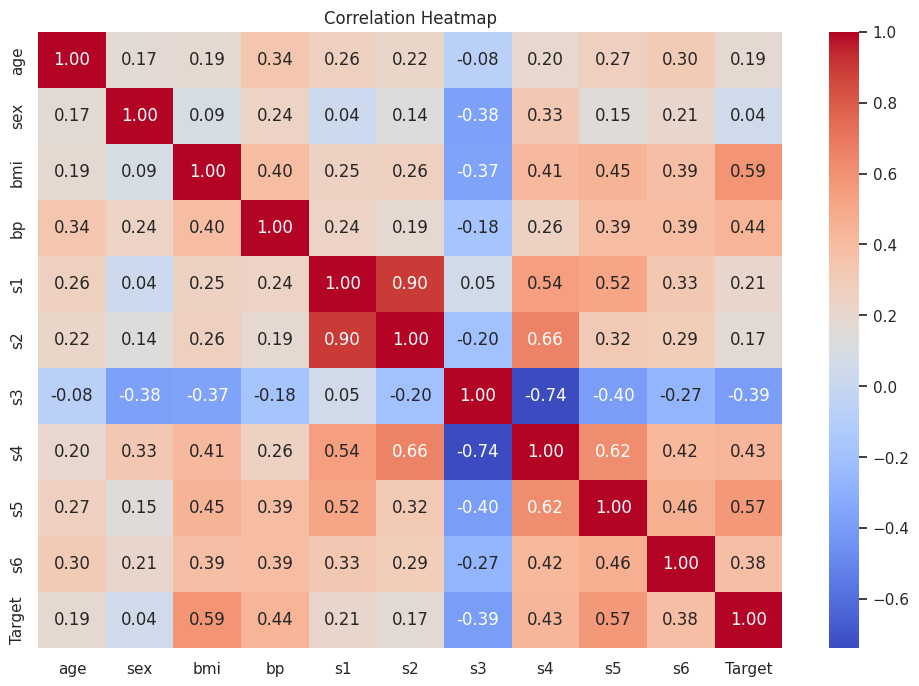

In [9]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()


## 9. Separate Features and Target

`X` contains the input features, while `y` contains the value that the model will learn to predict.

In [10]:
X = df.drop(columns="Target")
y = df["Target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (442, 10)
Target shape: (442,)


## 10. Train-Test Split

We keep 20% of the data for final testing and use the remaining 80% for model development.

The test set is kept separate so that it provides an unbiased evaluation after model selection.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)


Training features: (353, 10)
Testing features: (89, 10)


## 11. Build an SVR Pipeline

SVR is sensitive to feature scale because it uses distances and a margin-based optimization process. `StandardScaler` standardizes the input features.

A Pipeline ensures that scaling is fitted only on the training data in each cross-validation fold, helping prevent data leakage.

In [12]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR())
])

pipeline


Pipeline(steps=[('scaler', StandardScaler()), ('svr', SVR())])

## 12. Baseline Model with Cross-Validation

Before tuning, we evaluate a default SVR model using 5-fold cross-validation.

`KFold` divides the training data into five parts. In each round, four parts are used for training and one part for validation. We use negative mean absolute error because Scikit-learn follows a convention where larger scores are better; we convert the scores back to positive MAE values.

In [13]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=kfold,
    scoring="neg_mean_absolute_error"
)

mae_scores = -cv_scores

print("MAE for each fold:", mae_scores)
print("Average CV MAE:", mae_scores.mean())


MAE for each fold: [61.06040901 65.94056316 52.69873112 59.8427365  66.13861168]
Average CV MAE: 61.13621029169766


## 13. Hyperparameter Tuning using GridSearchCV

SVR performance depends on its kernel and hyperparameters.

- `C`: Controls the penalty for prediction errors. Larger values give the model more flexibility to fit the training data.
- `epsilon`: Defines the width of the margin around the regression function where errors are not penalized.
- `gamma`: Controls how far the influence of a training point reaches for the RBF kernel.
- `kernel`: Defines the type of function used to model the relationship.

GridSearchCV tests the combinations using 5-fold cross-validation and selects the combination with the lowest validation MAE.

In [14]:
param_grid = {
    "svr__kernel": ["linear", "rbf", "poly"],
    "svr__C": [0.1, 1, 10, 100],
    "svr__epsilon": [0.01, 0.1, 0.2, 0.5],
    "svr__gamma": ["scale", "auto"]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=kfold,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV MAE:", -grid_search.best_score_)


Best parameters: {'svr__C': 1, 'svr__epsilon': 0.5, 'svr__gamma': 'scale', 'svr__kernel': 'linear'}
Best CV MAE: 45.460643415052886


## 14. Compare Cross-Validation Results

We convert the grid-search results into a DataFrame and inspect the combinations with the lowest mean validation MAE.

Interpretation:
- Lower `mean_test_MAE` indicates a smaller average absolute prediction error during cross-validation.
- The standard deviation shows how much the validation error varied across folds.
- A small difference between combinations should not automatically be treated as a meaningful improvement.

In [15]:
cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results["mean_test_MAE"] = -cv_results["mean_test_score"]

cv_results[[
    "param_svr__kernel",
    "param_svr__C",
    "param_svr__epsilon",
    "param_svr__gamma",
    "mean_test_MAE",
    "std_test_score"
]].sort_values("mean_test_MAE").head(10)


,param_svr__kernel,param_svr__C,param_svr__epsilon,param_svr__gamma,mean_test_MAE,std_test_score
42,linear,1.0,0.50,scale,45.460643,2.364160
45,linear,1.0,0.50,auto,45.460643,2.364160
36,linear,1.0,0.20,scale,45.500532,2.352912
39,linear,1.0,0.20,auto,45.500532,2.352912
30,linear,1.0,0.10,scale,45.507004,2.340660
33,linear,1.0,0.10,auto,45.507004,2.340660
27,linear,1.0,0.01,auto,45.518036,2.327197
24,linear,1.0,0.01,scale,45.518036,2.327197
69,linear,10.0,0.50,auto,45.938735,1.480020
66,linear,10.0,0.50,scale,45.938735,1.480020


## 15. Visualize the Best Hyperparameter Combinations

The bar chart compares the ten best parameter combinations according to cross-validation MAE.

Interpretation:
- Each bar represents one hyperparameter combination.
- Shorter bars indicate lower average validation MAE.
- The chart helps us compare the best combinations visually; the final selection is still based on GridSearchCV's validation score.

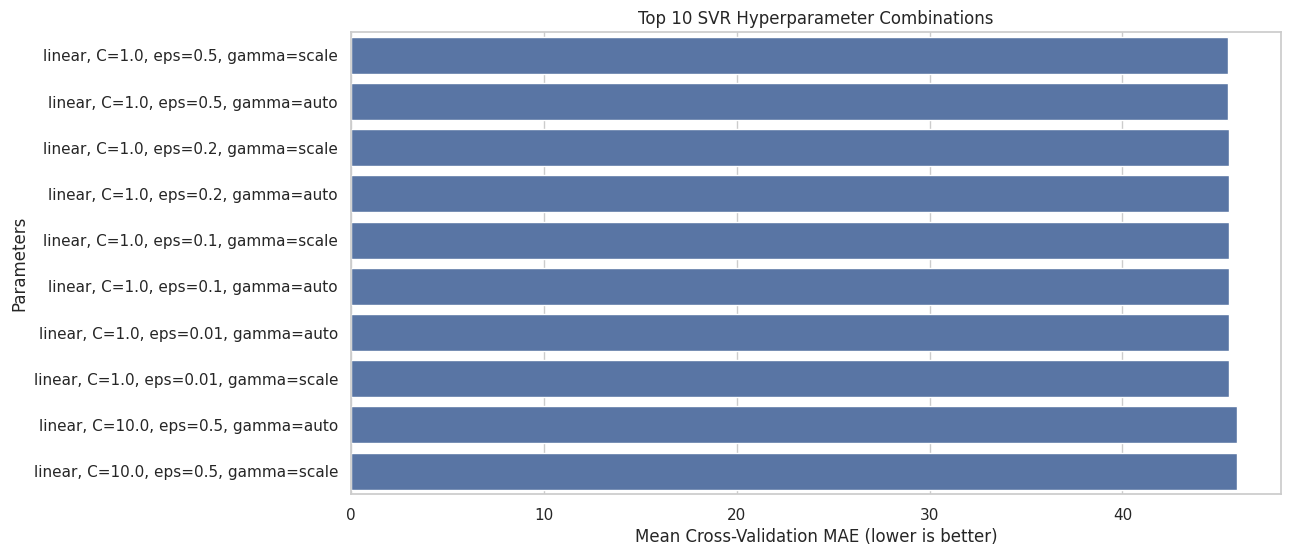

In [16]:
top_results = cv_results.sort_values("mean_test_MAE").head(10).copy()
top_results["Combination"] = [
    f"{row['param_svr__kernel']}, C={row['param_svr__C']}, eps={row['param_svr__epsilon']}, gamma={row['param_svr__gamma']}"
    for _, row in top_results.iterrows()
]

plt.figure(figsize=(12, 6))
sns.barplot(data=top_results, x="mean_test_MAE", y="Combination")
plt.title("Top 10 SVR Hyperparameter Combinations")
plt.xlabel("Mean Cross-Validation MAE (lower is better)")
plt.ylabel("Parameters")
plt.show()


## 16. Select the Best Model

`best_estimator_` returns the complete pipeline with the best hyperparameters found by GridSearchCV. We use this model for predictions.

In [17]:
best_model = grid_search.best_estimator_

print(best_model)


Pipeline(steps=[('scaler', StandardScaler()),
                ('svr', SVR(C=1, epsilon=0.5, kernel='linear'))])


## 17. Make Predictions on Test Data

We predict the target values for the test set. These observations were not used to fit or tune the model.

In [18]:
y_pred = best_model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results.head(10)


,Actual,Predicted
0,219.0,134.378536
1,70.0,177.621901
2,202.0,133.667299
3,230.0,286.987455
4,111.0,117.685963
5,84.0,92.478858
6,242.0,238.206934
7,272.0,178.295538
8,94.0,85.536261
9,96.0,105.412326


## 18. Evaluate the Model

We calculate four common regression metrics.

- MAE: Average absolute difference between actual and predicted values. Lower is better.
- MSE: Average squared prediction error. It penalizes larger errors more heavily.
- RMSE: Square root of MSE, expressed in the same unit as the target. Lower is better.
- R²: Measures how much variation in the target is explained by the model. A value closer to 1 generally indicates a better fit; it can be negative.

The metrics should be interpreted together rather than relying on only one score.

In [19]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


MAE: 43.32497331181277
MSE: 2936.3428267529835
RMSE: 54.18803213582297
R2 Score: 0.44577978017048814


## 19. Actual vs Predicted Values

This scatter plot compares the model's predictions with the actual target values. The diagonal line represents perfect predictions.

How to interpret the graph after running the notebook:
- Look at how closely the points follow the diagonal line. Points close to it are predictions close to the actual values.
- Points above the line mean the model predicted a value higher than the actual value (overprediction).
- Points below the line mean the model predicted a value lower than the actual value (underprediction).
- In this dataset, predictions should be judged by the overall spread around the line, not by one or two points. A wide spread means prediction errors are substantial for some observations.
- The graph complements MAE, RMSE, and R² by showing where predictions are close or far from actual values.


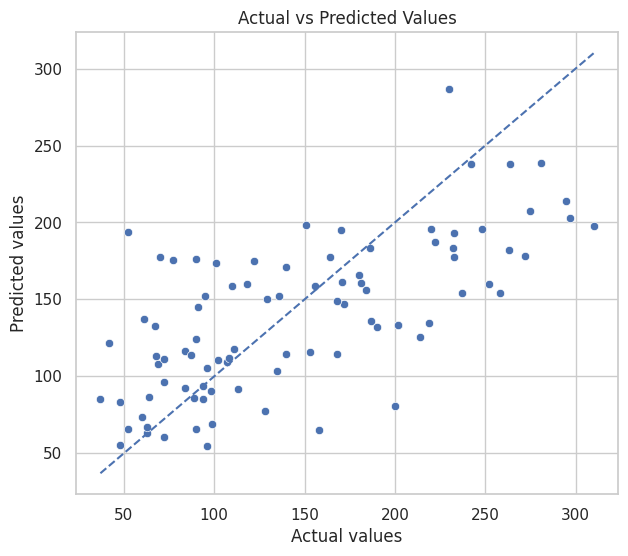

In [20]:
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=y_pred)
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.title("Actual vs Predicted Values")
plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.show()


## 20. Residual Analysis

A residual is the difference between an actual value and its prediction.

Residual = Actual value - Predicted value

A residual plot helps us check whether prediction errors show a pattern.

How to interpret the graph after running the notebook:
- Points above the zero line have positive residuals: the model underpredicted those observations.
- Points below the zero line have negative residuals: the model overpredicted those observations.
- A random cloud around zero is generally desirable because it suggests that errors do not follow an obvious pattern.
- A curve or other systematic shape suggests the model may be missing some relationship.
- If the vertical spread becomes wider or narrower across predicted values, the error variance may not be constant.


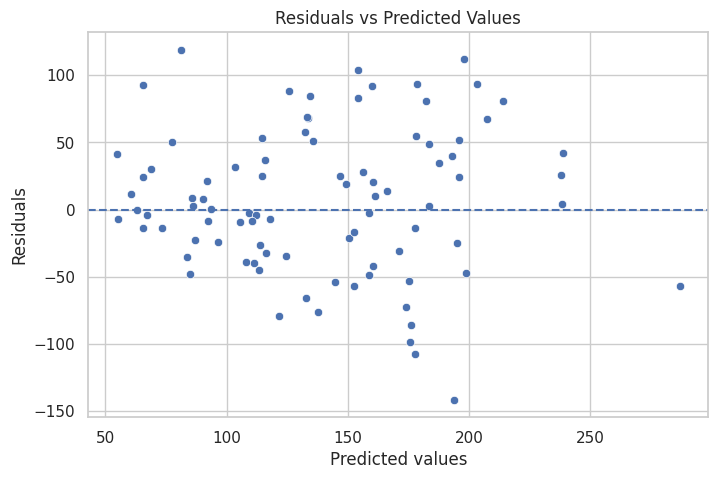

In [21]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(y=0, linestyle="--")
plt.title("Residuals vs Predicted Values")
plt.xlabel("Predicted values")
plt.ylabel("Residuals")
plt.show()


## 21. Distribution of Residuals

The histogram with KDE shows the distribution of prediction errors.

How to interpret this graph after running the notebook:
- The dashed vertical line marks zero error.
- Bars to the right represent positive residuals (underpredictions); bars to the left represent negative residuals (overpredictions).
- A distribution centered near zero suggests that the model does not consistently overpredict or underpredict overall.
- A long tail or isolated bars far from zero indicate some observations have relatively large errors.
- A roughly symmetric shape is often desirable, but residuals do not have to be perfectly normal for the model to be useful.


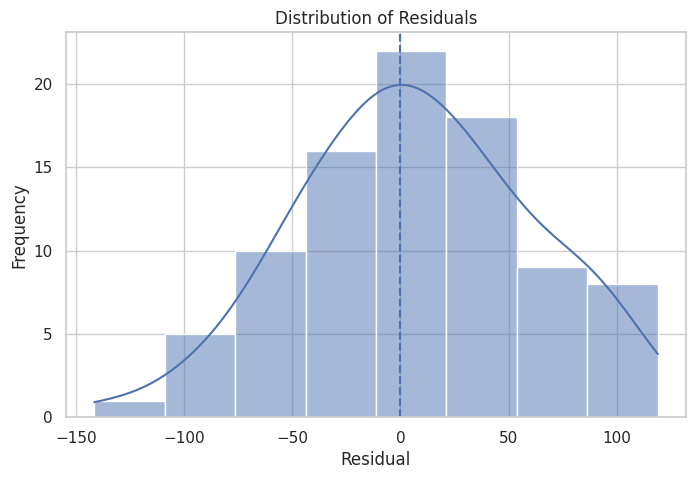

In [22]:
plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True)
plt.axvline(0, linestyle="--")
plt.title("Distribution of Residuals")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.show()


## 22. Inspect the Largest Prediction Errors

We calculate the absolute error for each test observation and display the observations with the largest errors. This helps us inspect where the model struggled most.

In [23]:
results["Absolute Error"] = np.abs(results["Actual"] - results["Predicted"])

results.sort_values("Absolute Error", ascending=False).head(10)


,Actual,Predicted,Absolute Error
61,52.0,193.703089,141.703089
46,200.0,80.943552,119.056448
20,310.0,197.637718,112.362282
1,70.0,177.621901,107.621901
49,258.0,154.079304,103.920696
27,77.0,175.393324,98.393324
13,297.0,203.112406,93.887594
7,272.0,178.295538,93.704462
51,158.0,65.419719,92.580281
11,252.0,159.891177,92.108823


## 23. Conclusion

In this project, I used Support Vector Regression (SVR) to predict diabetes disease progression using the Scikit-learn Diabetes dataset.

I performed exploratory data analysis, examined feature distributions and correlations, split the data into training and testing sets, and created a preprocessing pipeline using StandardScaler and SVR. I used 5-fold cross-validation and GridSearchCV to select hyperparameters based on validation MAE.

Finally, I evaluated the selected model on unseen test data using MAE, MSE, RMSE, and R², and inspected actual-versus-predicted values and residual plots.

